# 01 · Data audit

Checks questions 1–18 from `analysis_questions.md` against the **raw** Excel file.
Every check records a row in `findings`. Status: **PASS** (clean), **WARN** (worth knowing; handled or low impact),
**FAIL** (wrong data that affects numbers or needs a fix at the source).

Outputs: `output/audit_findings.csv`, `output/audit_exceptions.xlsx` (one sheet of offending rows per check),
charts in `output/figures/`.

In [1]:
import sys, re
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.metrics import (load_raw, load_clean, dedupe_customers, reconcile, RAW_PATH,
                         DATA_DIR, OUTPUT_DIR, DATA_END, NON_REVENUE_STATUSES)
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid", palette=["#0E7C86", "#F2A541", "#14213D", "#E4572E", "#5B6C8F"])
DATA_DIR.mkdir(parents=True, exist_ok=True); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"; FIG_DIR.mkdir(exist_ok=True)

In [2]:
raw = load_raw()
cust_raw, prod, oi = raw["Customers"].copy(), raw["Products"].copy(), raw["Order_Items"].copy()
d = load_clean()
cust, lines, orders = d["customers"], d["lines"], d["orders"]

findings, exceptions = [], {}
def record(qid, area, check, status, count, detail, rows=None):
    findings.append(dict(q=qid, area=area, check=check, status=status, count=int(count), detail=detail))
    if rows is not None and len(rows):
        exceptions[f"Q{qid:02d} {check}"[:31]] = rows
    print(f"[{status}] Q{qid} {check}: {detail}")
print({k: v.shape for k, v in raw.items()})

{'Customers': (307, 12), 'Products': (200, 9), 'Order_Items': (1500, 15)}


## A. Completeness and uniqueness

### Q1 · Duplicate customer IDs: which fields differ between copies?

In [3]:
cid = cust_raw["customer_id"]
blank_ids = cust_raw[cid.isna() | (cid.astype(str).str.strip() == "")]
dups = cust_raw[cid.notna() & cid.duplicated(keep=False)].sort_values("customer_id")
diff_cols = (dups.groupby("customer_id").nunique(dropna=False) > 1)
diff_summary = diff_cols.apply(lambda r: ", ".join(r.index[r]), axis=1)
display(dups.drop(columns=["first_name", "last_name", "email", "phone", "birth_date"], errors='ignore'))   # personal fields hidden
display(diff_summary.rename("fields that differ").to_frame())
# Are the extra copies strict subsets of the complete row? (nothing to merge in)
def is_subset(g):
    full = g.loc[g.notna().sum(axis=1).idxmax()]
    others = g.drop(index=full.name)
    return all(((o.isna()) | (o == full)).all() for _, o in others.iterrows())
subset = dups.groupby("customer_id").apply(is_subset, include_groups=False)
record(1, "Completeness", "Duplicate customer IDs", "FAIL" if len(dups) else "PASS", dups["customer_id"].nunique(),
       f"{len(cust_raw)} rows, {cid.nunique()} IDs; {dups.customer_id.nunique()} IDs duplicated "
       f"({len(dups)} rows); {len(blank_ids)} blank ID row(s). Copies are subsets of the full row: "
       f"{dict(subset)}. Keep-most-complete loses nothing only where True.",
       pd.concat([dups, blank_ids]))
display(blank_ids.drop(columns=["first_name", "last_name", "email", "phone", "birth_date"], errors='ignore'))

,customer_id,join_date,city,state,country,segment,gender
0,CUST0001,2022-10-09,Bengaluru,Karnataka,India,Retail,Other
36,CUST0001,2022-10-09,NaN,NaN,NaN,NaN,NaN
37,CUST0001,2022-10-09,Bengaluru,NaN,NaN,NaN,NaN
38,CUST0001,NaT,Bengaluru,NaN,NaN,NaN,NaN
227,CUST0300,NaT,NaN,NaN,NaN,NaN,NaN
230,CUST0300,NaT,NaN,NaN,NaN,NaN,NaN
306,CUST0300,2023-09-11,Nagpur,Maharashtra,India,Retail,Male


,fields that differ
customer_id,
CUST0001,"phone, join_date, city, state, country, segmen..."
CUST0300,"first_name, last_name, email, phone, join_date..."


[FAIL] Q1 Duplicate customer IDs: 307 rows, 301 IDs; 2 IDs duplicated (7 rows); 1 blank ID row(s). Copies are subsets of the full row: {'CUST0001': np.True_, 'CUST0300': np.False_}. Keep-most-complete loses nothing only where True.


,customer_id,join_date,city,state,country,segment,gender
229,NaN,2023-07-10,Chennai,Tamil Nadu,India,Wholesale,Male


### Q2 · Missing values: how often, and are they random?

,,nulls
Order_Items,order_date,23


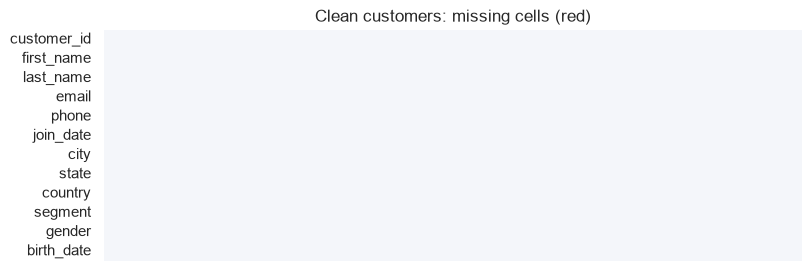

[WARN] Q2 Missing values: Nulls after dedupe: Order_Items.order_date=23


In [4]:
miss = pd.concat({name: df.isna().sum() for name, df in
                  {"Customers (clean)": cust[cust_raw.columns], "Products": prod, "Order_Items": oi}.items()}, axis=0)
miss = miss[miss > 0].rename("nulls").to_frame()
display(miss)
fig, ax = plt.subplots(figsize=(9, 3))
sns.heatmap(cust[cust_raw.columns].isna().T, cbar=False, ax=ax, cmap=["#F4F6FA", "#E4572E"])
ax.set_title("Clean customers: missing cells (red)"); ax.set_xticks([])
fig.savefig(FIG_DIR / "q02_missing_customers.png", dpi=150, bbox_inches="tight"); plt.show()
missing_rows = cust[cust[cust_raw.columns].isna().any(axis=1)]
record(2, "Completeness", "Missing values", "WARN" if len(miss) else "PASS", int(miss["nulls"].sum()) if len(miss) else 0,
       "Nulls after dedupe: " + (", ".join(f"{i[0]}.{i[1]}={v}" for i, v in miss["nulls"].items()) or "none"),
       missing_rows)

### Q2b · Missing order dates: recoverable from the same order?

In [5]:
nd = oi[oi["order_date"].isna()]
per_order = oi[oi["order_id"].isin(nd["order_id"])].groupby("order_id")["order_date"].agg(["count", "size", "nunique"])
unrecoverable = per_order[per_order["count"] == 0]
display(nd["order_status"].value_counts().rename("lines").to_frame().T)
record(2, "Completeness", "Missing order dates", "FAIL" if len(unrecoverable) else "WARN", len(nd),
       f"{len(nd)} lines in {nd.order_id.nunique()} orders have no order_date (statuses: {nd.order_status.value_counts().to_dict()}). "
       f"{len(per_order) - len(unrecoverable)} of {len(per_order)} orders have the date on another line with one distinct value, "
       f"so it is filled from the order (flag: lines.order_date_imputed). Power BI's Order_Items query applies the same fill.", nd)
dd = cust_raw.dropna(subset=["customer_id"]).copy(); dd["_n"] = dd.notna().sum(axis=1)
dd = dd.sort_values(["customer_id", "_n"], ascending=[True, False]).drop_duplicates("customer_id")
stub = dd[dd[["email", "segment", "join_date"]].isna().all(axis=1)].drop(columns="_n")
record(2, "Completeness", "Stub customer rows", "WARN" if len(stub) else "PASS", len(stub),
       f"{len(stub)} customer(s) with only an ID and first name and no orders: {stub.customer_id.tolist()} (now dropped in Power BI and Python). "
       f"Raw CUST0300 copies carry different first names (Roni, Ritesh vs Rhea): possibly different people sharing an ID.",
       stub)

order_status,Cancelled
lines,23


[WARN] Q2 Missing order dates: 23 lines in 13 orders have no order_date (statuses: {'Cancelled': 23}). 13 of 13 orders have the date on another line with one distinct value, so it is filled from the order (flag: lines.order_date_imputed). Power BI's Order_Items query applies the same fill.
[WARN] Q2 Stub customer rows: 1 customer(s) with only an ID and first name and no orders: ['CUST0301'] (now dropped in Power BI and Python). Raw CUST0300 copies carry different first names (Roni, Ritesh vs Rhea): possibly different people sharing an ID.


### Q3 · Primary keys and SKUs unique?

In [6]:
checks = {
    "order_item_id": oi["order_item_id"], "product_id": prod["product_id"], "sku": prod["sku"],
    "product_name": prod["product_name"], "email (clean customers)": cust["email"].dropna(),
}
res = {k: int(s.duplicated().sum()) for k, s in checks.items()}
display(pd.Series(res, name="duplicates"))
bad = {k: v for k, v in res.items() if v}
dup_names = prod[prod["product_name"].duplicated(keep=False)].sort_values("product_name")
record(3, "Uniqueness", "Keys and SKUs unique", "WARN" if bad else "PASS", sum(bad.values()),
       f"Duplicates: {bad or 'none'}", dup_names)

order_item_id              0
product_id                 0
sku                        0
product_name               0
email (clean customers)    0
Name: duplicates, dtype: int64

[PASS] Q3 Keys and SKUs unique: Duplicates: none


### Q4 · Orphan keys between sheets

In [7]:
orph_c = oi[~oi["customer_id"].isin(cust["customer_id"])]
orph_p = oi[~oi["product_id"].isin(prod["product_id"])]
never_sold = prod[~prod["product_id"].isin(oi["product_id"])]
never_ordered = cust[cust["lifetime_orders"] == 0]
record(4, "Integrity", "Orphan keys", "FAIL" if len(orph_c) + len(orph_p) else "PASS", len(orph_c) + len(orph_p),
       f"{len(orph_c)} lines with unknown customer, {len(orph_p)} with unknown product. "
       f"(Info: {len(never_sold)} products never sold, {len(never_ordered)} customers never ordered.)",
       pd.concat([orph_c, orph_p]))

[PASS] Q4 Orphan keys: 0 lines with unknown customer, 0 with unknown product. (Info: 0 products never sold, 80 customers never ordered.)


### Q5 · Is every order header consistent across its lines?

In [8]:
hdr = ["order_date", "customer_id", "order_status", "payment_method", "discount_percent", "items_total", "total_amount"]
nun = oi.groupby("order_id")[hdr].nunique()
inconsistent = nun[(nun > 1).any(axis=1)]
display(nun.max().rename("max distinct values per order").to_frame())
record(5, "Integrity", "Order header consistent", "FAIL" if len(inconsistent) else "PASS", len(inconsistent),
       f"{len(inconsistent)} of {oi.order_id.nunique()} orders have conflicting header fields across lines",
       oi[oi["order_id"].isin(inconsistent.index)])

,max distinct values per order
order_date,1
customer_id,1
order_status,1
payment_method,1
discount_percent,1
items_total,1
total_amount,1


[PASS] Q5 Order header consistent: 0 of 405 orders have conflicting header fields across lines


## B. Consistency and validity

### Q6 · `items_total` = Σ `line_total` per order?  Also: is `line_total` itself computed correctly?

In [9]:
orders["items_vs_lines"] = (orders["items_total"] - orders["line_total_sum"]).round(2)
bad_it = orders[orders["items_vs_lines"].abs() > 1]
calc = oi["unit_price"] * oi["quantity"] * (1 - oi["item_discount_percent"]/100) * (1 + oi["tax_percent"]/100)
bad_lt = oi[(calc - oi["line_total"]).abs() > 1]
inflation = oi["items_total"].sum() / oi["line_total"].sum()
record(6, "Consistency", "Order totals reconcile", "FAIL" if len(bad_it) or len(bad_lt) else "PASS",
       len(bad_it) + len(bad_lt),
       f"{len(bad_it)} orders where items_total != sum(line_total); {len(bad_lt)} lines where line_total != formula. "
       f"Summing items_total across lines would overstate by {inflation:.2f}x.", pd.concat([bad_it, bad_lt]))

[PASS] Q6 Order totals reconcile: 0 orders where items_total != sum(line_total); 0 lines where line_total != formula. Summing items_total across lines would overstate by 4.64x.


### Q7 · Implied shipping: known tiers? What drives the tier?

In [10]:
tiers = orders["implied_shipping"].round(0)
display(tiers.value_counts().sort_index().rename("orders").to_frame().T)
odd = orders[~tiers.isin([0, 30, 50, 60, 70, 100, 140, 150, 200, 300])]
orders["value_band"] = pd.qcut(orders["items_total"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
ship_by = orders.merge(cust[["customer_id", "state"]], on="customer_id", how="left")
display(ship_by.groupby("value_band", observed=True)["implied_shipping"].agg(["mean", "median", "min", "max"]))
display(ship_by.groupby("payment_method")["implied_shipping"].mean().rename("avg shipping").to_frame().T)
corr = orders["implied_shipping"].corr(orders["items_total"])
record(7, "Consistency", "Implied shipping tiers", "WARN" if len(odd) else "PASS", len(odd),
       f"{tiers.nunique()} distinct shipping values, {len(odd)} outside known tiers; correlation with order value {corr:.2f} "
       f"(no clear rule; shipping is not a column, so it cannot be audited against a rate card)", odd)

implied_shipping,0.00,30.00,50.00,60.00,70.00,100.00,140.00,150.00,200.00,300.00
orders,63,50,40,16,57,76,16,60,13,14


,mean,median,min,max
value_band,,,,
Q1 low,83.92,70.00,0.00,300.00
Q2,76.04,70.00,0.00,300.00
Q3,84.16,70.00,-0.00,300.00
Q4 high,92.57,70.00,-0.01,300.00


payment_method,Cash on Delivery,Credit Card,Debit Card,Netbanking,UPI
avg shipping,68.12,86.07,76.41,99.15,83.10


[PASS] Q7 Implied shipping tiers: 10 distinct shipping values, 0 outside known tiers; correlation with order value 0.07 (no clear rule; shipping is not a column, so it cannot be audited against a rate card)


### Q8 · Order price vs product list price

In [11]:
pm = lines[(lines["unit_price"] - lines["list_price"]).abs() > 0.01]
record(8, "Consistency", "Order price = list price", "WARN" if len(pm) else "PASS", len(pm),
       f"{len(pm)} lines priced differently from Products.unit_price (prices appear static over 2023-2025: "
       f"no price history to audit)", pm)

[PASS] Q8 Order price = list price: 0 lines priced differently from Products.unit_price (prices appear static over 2023-2025: no price history to audit)


### Q9 · Cost below price? Margin distribution by category

,count,min,50%,max
category,,,,
Beauty,44.00,0.15,0.35,0.54
Electronics,38.00,0.16,0.31,0.54
Fashion,42.00,0.15,0.36,0.53
Home & Kitchen,36.00,0.16,0.34,0.54
Sports,40.00,0.15,0.36,0.53


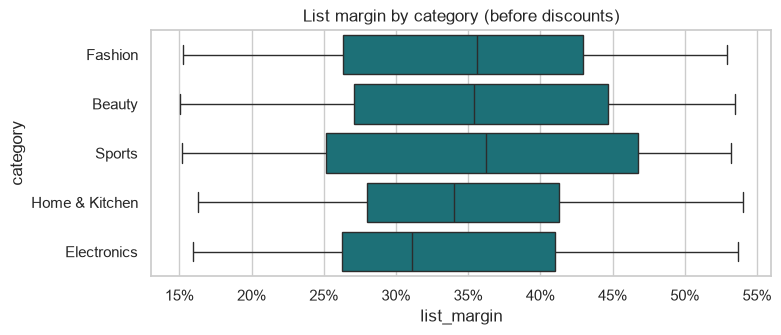

[PASS] Q9 Cost below price: 0 products with cost >= price; list margin ranges 15%-54%


In [12]:
prod["list_margin"] = 1 - prod["cost_price"] / prod["unit_price"]
neg = prod[prod["cost_price"] >= prod["unit_price"]]
display(prod.groupby("category")["list_margin"].describe()[["count", "min", "50%", "max"]])
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.boxplot(data=prod, x="list_margin", y="category", ax=ax)
ax.set_title("List margin by category (before discounts)"); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.savefig(FIG_DIR / "q09_list_margin.png", dpi=150, bbox_inches="tight"); plt.show()
record(9, "Validity", "Cost below price", "FAIL" if len(neg) else "PASS", len(neg),
       f"{len(neg)} products with cost >= price; list margin ranges {prod.list_margin.min():.0%}-{prod.list_margin.max():.0%}", neg)

### Q10 · Do SKU prefixes mean anything?

In [13]:
prod["sku_prefix"] = prod["sku"].str.split("-").str[0]
xt = pd.crosstab(prod["sku_prefix"], prod["category"])
display(xt)
# expected prefix = first two letters of the category
prod["expected_prefix"] = prod["category"].str[:2].str.upper()
mismatch = prod[prod["sku_prefix"] != prod["expected_prefix"]]
sku_num_ok = (prod["sku"].str.split("-").str[1].astype(int) == prod["product_id"].str[4:].astype(int)).mean()
record(10, "Validity", "SKU prefix vs category", "FAIL" if len(mismatch) > len(prod) * 0.2 else "WARN", len(mismatch),
       f"{len(mismatch)} of {len(prod)} SKUs have a prefix that does not match their category (looks randomly assigned); "
       f"SKU number matches product_id for {sku_num_ok:.0%} of products", mismatch)

category,Beauty,Electronics,Fashion,Home & Kitchen,Sports
sku_prefix,,,,,
BE,9,6,9,7,10
EL,12,10,11,11,10
FA,9,4,9,3,8
HK,8,11,4,9,5
SP,6,7,9,6,7


[FAIL] Q10 SKU prefix vs category: 165 of 200 SKUs have a prefix that does not match their category (looks randomly assigned); SKU number matches product_id for 100% of products


### Q11 · Allowed discount and tax values; does tax follow category (GST)?

In [14]:
display(pd.DataFrame({c: oi[c].value_counts().sort_index() for c in ["discount_percent", "item_discount_percent", "tax_percent"]}))
tax_by_sub = lines.groupby("subcategory")["tax_percent"].nunique()
display(pd.crosstab(lines["category"], lines["tax_percent"]))
multi = tax_by_sub[tax_by_sub > 1]
record(11, "Validity", "Tax follows product (GST)", "FAIL" if len(multi) else "PASS", len(multi),
       f"Discounts only 0/5/10/15 and tax only 0/5/12/18 (valid sets), but {len(multi)} of {len(tax_by_sub)} subcategories "
       f"carry more than one tax rate; the same product type is taxed at 0% and 18% in different orders",
       lines[lines["subcategory"].isin(multi.index)][["order_item_id", "product_id", "subcategory", "tax_percent"]])

,discount_percent,item_discount_percent,tax_percent
0,671.00,741.00,151.00
5,301.00,263.00,597.00
10,257.00,236.00,NaN
12,NaN,NaN,434.00
15,271.00,260.00,NaN
18,NaN,NaN,318.00


tax_percent,0,5,12,18
category,,,,
Beauty,35,132,96,74
Electronics,19,121,84,58
Fashion,33,122,93,67
Home & Kitchen,26,115,65,56
Sports,38,107,96,63


[FAIL] Q11 Tax follows product (GST): Discounts only 0/5/10/15 and tax only 0/5/12/18 (valid sets), but 25 of 25 subcategories carry more than one tax rate; the same product type is taxed at 0% and 18% in different orders


### Q12 · Date validity: order vs join date, ages, ranges

In [15]:
x = lines.merge(cust[["customer_id", "join_date", "birth_date"]], on="customer_id", how="left")
before_join = x[x["order_date"] < x["join_date"]].drop_duplicates("order_id")
age = (DATA_END - cust["birth_date"]).dt.days / 365.25
age_bad = cust[(age < 18) | (age > 100)]
future = oi[oi["order_date"] > DATA_END]
print("order_date:", oi.order_date.min().date(), "to", oi.order_date.max().date(),
      "| join_date:", cust.join_date.min().date(), "to", cust.join_date.max().date(),
      "| age:", f"{age.min():.0f}-{age.max():.0f}")
joined_after_last_order = cust[cust["join_date"] > DATA_END]
record(12, "Validity", "Dates plausible", "FAIL" if len(before_join) else "PASS", len(before_join) + len(age_bad),
       f"{len(before_join)} orders placed before the customer's join_date; {len(age_bad)} customers aged <18 or >100; "
       f"{len(future)} future-dated orders", before_join)

order_date: 2023-01-09 to 2025-10-31 | join_date: 2022-01-01 to 2024-09-25 | age: 22-65


[FAIL] Q12 Dates plausible: 73 orders placed before the customer's join_date; 0 customers aged <18 or >100; 0 future-dated orders


### Q13 · Phone and email validity

In [16]:
phone = cust["phone"].dropna().astype("int64").astype(str)
bad_phone = cust.loc[phone.index][~phone.str.fullmatch(r"[6-9]\d{9}")]
email_ok = cust["email"].dropna().str.fullmatch(r"[^@\s]+@[^@\s]+\.[a-z]{2,}")
bad_email = cust.loc[email_ok[~email_ok].index]
name_match = cust.dropna(subset=["email"]).apply(
    lambda r: str(r["first_name"]).lower() in r["email"] and str(r["last_name"]).lower() in r["email"], axis=1)
record(13, "Validity", "Phone and email", "FAIL" if len(bad_phone) + len(bad_email) else "PASS", len(bad_phone) + len(bad_email),
       f"{len(bad_phone)} invalid phones, {len(bad_email)} invalid emails, {cust.email.duplicated().sum()} duplicate emails; "
       f"emails match the customer name for {name_match.mean():.0%}. All domains are example.com (synthetic/test data).",
       pd.concat([bad_phone, bad_email]))

[PASS] Q13 Phone and email: 0 invalid phones, 0 invalid emails, 0 duplicate emails; emails match the customer name for 100%. All domains are example.com (synthetic/test data).

### Q14 · Geography: does each city sit in one state? Country values

In [17]:
city_states = cust.dropna(subset=["city", "state"]).groupby("city")["state"].nunique()
conflict = city_states[city_states > 1]
display(cust.groupby(["state", "city"]).size().rename("customers").to_frame().head(40))
record(14, "Validity", "City-state consistency", "FAIL" if len(conflict) else "PASS", len(conflict),
       f"{len(conflict)} cities mapped to more than one state; countries: {cust.country.dropna().unique().tolist()}",
       cust[cust["city"].isin(conflict.index)].sort_values("city"))

customers
state          city                    
Andhra Pradesh Visakhapatnam         26
Bihar          Patna                 14
Delhi          Delhi                 19
Gujarat        Ahmedabad             22
               Surat                 25
Karnataka      Bengaluru             27
Madhya Pradesh Bhopal                18
Maharashtra    Mumbai                25
               Nagpur                19
               Pune                  21
Rajasthan      Jaipur                19
Tamil Nadu     Chennai               14
Telangana      Hyderabad             15
Uttar Pradesh  Lucknow               23
West Bengal    Kolkata               13

[PASS] Q14 City-state consistency: 0 cities mapped to more than one state; countries: ['India']


### Q15 · Stock quantity vs units sold

In [18]:
sold = lines[lines["is_revenue"]].groupby("product_id")["quantity"].sum()
st = prod.set_index("product_id")[["product_name", "category", "stock_quantity"]].join(sold.rename("units_sold")).fillna({"units_sold": 0})
st["cover_years"] = st["stock_quantity"] / (st["units_sold"] / (34 / 12)).replace(0, np.nan)
display(st.describe()[["stock_quantity", "units_sold", "cover_years"]])
record(15, "Validity", "Stock vs sales", "WARN", int((st["cover_years"] > 50).sum()),
       f"Stock {st.stock_quantity.min()}-{st.stock_quantity.max()} units/product vs avg {st.units_sold.mean():.1f} units sold in 34 months; "
       f"median cover {st.cover_years.median():.0f} years. stock_quantity is a static snapshot unrelated to sales; "
       f"not usable for inventory analysis", st.reset_index())

,stock_quantity,units_sold,cover_years
count,200.00,200.00,200.00
mean,519.85,9.67,199.06
std,305.11,4.01,189.87
min,0.00,1.00,0.00
25%,246.75,7.00,68.92
50%,548.00,9.00,158.46
75%,802.75,12.00,246.73
max,997.00,21.00,"1,214.08"


[WARN] Q15 Stock vs sales: Stock 0-997 units/product vs avg 9.7 units sold in 34 months; median cover 158 years. stock_quantity is a static snapshot unrelated to sales; not usable for inventory analysis


## C. Business-rule checks

### Q16 · Loss-making lines

In [19]:
loss = lines[lines["is_revenue"] & (lines["gross_profit"] < 0)]
combo = loss.groupby(["item_discount_percent", "discount_percent"]).size().rename("lines").reset_index()
display(combo)
stacked = loss[(loss["item_discount_percent"] > 0) & (loss["discount_percent"] > 0)]
record(16, "Business rule", "Sold below cost", "WARN" if len(loss) else "PASS", len(loss),
       f"{len(loss)} revenue lines below cost, total {loss.gross_profit.sum():,.0f}; {len(stacked)} of them stack an item "
       f"and an order discount; {(loss.item_discount_percent == 15).sum()} carry the 15% item discount",
       loss[["order_item_id", "order_id", "product_id", "category", "cost_price", "item_discount_percent", "discount_percent", "net_sales", "cogs", "gross_profit"]])

,item_discount_percent,discount_percent,lines
0,5,15,4
1,10,10,4
2,10,15,4
3,15,5,2
4,15,10,5
5,15,15,10


[WARN] Q16 Sold below cost: 29 revenue lines below cost, total -107,236; 29 of them stack an item and an order discount; 17 carry the 15% item discount


### Q17 · Where do cancellations and returns cluster?

In [20]:
o = orders.merge(cust[["customer_id", "state", "segment"]], on="customer_id", how="left")
o["lost"] = ~o["is_revenue"]
by = {k: o.groupby(k, observed=True)["lost"].agg(["mean", "sum", "count"]).rename(columns={"mean": "rate", "sum": "lost_orders"})
      for k in ["payment_method", "value_band", "segment"]}
for k, v in by.items():
    display(v.sort_values("rate", ascending=False).style.format({"rate": "{:.1%}"}).set_caption(k))
top = by["payment_method"]["rate"].idxmax()
record(17, "Business rule", "Cancel/return clustering", "WARN", int(o["lost"].sum()),
       f"{o.lost.sum()} of {len(o)} orders cancelled/returned ({o.lost.mean():.1%}). Highest by payment: {top} "
       f"({by['payment_method'].loc[top, 'rate']:.1%}). Small counts; differences are not statistically strong.",
       o[o["lost"]])

,rate,lost_orders,count
payment_method,,,
Credit Card,6.4%,9,140
Debit Card,4.9%,5,103
UPI,4.6%,4,87
Netbanking,1.7%,1,59
Cash on Delivery,0.0%,0,16


,rate,lost_orders,count
value_band,,,
Q1 low,6.9%,7,102
Q4 high,5.9%,6,101
Q3,4.0%,4,101
Q2,2.0%,2,101


,rate,lost_orders,count
segment,,,
Wholesale,4.8%,4,83
Retail,4.7%,15,322


[WARN] Q17 Cancel/return clustering: 19 of 405 orders cancelled/returned (4.7%). Highest by payment: Credit Card (6.4%). Small counts; differences are not statistically strong.


### Q18 · Does `segment` match behaviour (Wholesale vs Retail)?

,orders,avg_units,avg_net_sales,avg_lines
segment,,,,
Retail,307,5.06,"286,971.75",3.78
Wholesale,79,4.84,"254,713.39",3.42


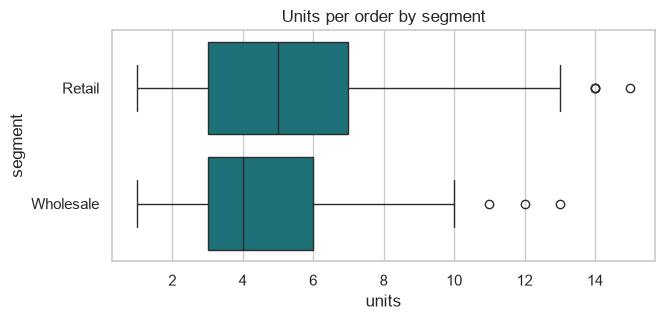

[WARN] Q18 Segment matches behaviour: Wholesale orders average 4.8 units vs Retail 5.1 (0.96x). Wholesale buyers do not buy in bulk; segment label is not reflected in behaviour


In [21]:
o2 = o[o["is_revenue"]]
seg = o2.groupby("segment").agg(orders=("order_id", "count"), avg_units=("units", "mean"),
                                avg_net_sales=("net_sales", "mean"), avg_lines=("lines", "mean"))
display(seg)
fig, ax = plt.subplots(figsize=(7, 3))
sns.boxplot(data=o2, x="units", y="segment", ax=ax); ax.set_title("Units per order by segment")
fig.savefig(FIG_DIR / "q18_units_by_segment.png", dpi=150, bbox_inches="tight"); plt.show()
ratio = seg.loc["Wholesale", "avg_units"] / seg.loc["Retail", "avg_units"]
record(18, "Business rule", "Segment matches behaviour", "WARN" if ratio < 1.5 else "PASS", 0,
       f"Wholesale orders average {seg.loc['Wholesale','avg_units']:.1f} units vs Retail {seg.loc['Retail','avg_units']:.1f} "
       f"({ratio:.2f}x). Wholesale buyers do not buy in bulk; segment label is not reflected in behaviour")

## Summary

In [22]:
F = pd.DataFrame(findings)
order = {"FAIL": 0, "WARN": 1, "PASS": 2}
F = F.sort_values(["status", "q"], key=lambda s: s.map(order) if s.name == "status" else s).reset_index(drop=True)
F.to_csv(OUTPUT_DIR / "audit_findings.csv", index=False)
with pd.ExcelWriter(OUTPUT_DIR / "audit_exceptions.xlsx") as xw:
    F.to_excel(xw, sheet_name="Summary", index=False)
    for name, rows in exceptions.items():
        rows.to_excel(xw, sheet_name=re.sub(r"[\[\]\*\?/\\:]", "", name)[:31], index=False)
display(F["status"].value_counts().rename("checks").to_frame().T)
F.style.apply(lambda r: [f"background-color: {'#FDE2DC' if r.status == 'FAIL' else '#FDF1DC' if r.status == 'WARN' else '#E3F4F1'}"] * len(r), axis=1)

status,PASS,WARN,FAIL
checks,9,7,4


,q,area,check,status,count,detail
0,1,Completeness,Duplicate customer IDs,FAIL,2,"307 rows, 301 IDs; 2 IDs duplicated (7 rows); 1 blank ID row(s). Copies are subsets of the full row: {'CUST0001': np.True_, 'CUST0300': np.False_}. Keep-most-complete loses nothing only where True."
1,10,Validity,SKU prefix vs category,FAIL,165,165 of 200 SKUs have a prefix that does not match their category (looks randomly assigned); SKU number matches product_id for 100% of products
2,11,Validity,Tax follows product (GST),FAIL,25,"Discounts only 0/5/10/15 and tax only 0/5/12/18 (valid sets), but 25 of 25 subcategories carry more than one tax rate; the same product type is taxed at 0% and 18% in different orders"
3,12,Validity,Dates plausible,FAIL,73,73 orders placed before the customer's join_date; 0 customers aged <18 or >100; 0 future-dated orders
4,2,Completeness,Missing values,WARN,23,Nulls after dedupe: Order_Items.order_date=23
5,2,Completeness,Missing order dates,WARN,23,"23 lines in 13 orders have no order_date (statuses: {'Cancelled': 23}). 13 of 13 orders have the date on another line with one distinct value, so it is filled from the order (flag: lines.order_date_imputed). Power BI's Order_Items query applies the same fill."
6,2,Completeness,Stub customer rows,WARN,1,"1 customer(s) with only an ID and first name and no orders: ['CUST0301'] (now dropped in Power BI and Python). Raw CUST0300 copies carry different first names (Roni, Ritesh vs Rhea): possibly different people sharing an ID."
7,15,Validity,Stock vs sales,WARN,163,Stock 0-997 units/product vs avg 9.7 units sold in 34 months; median cover 158 years. stock_quantity is a static snapshot unrelated to sales; not usable for inventory analysis
8,16,Business rule,Sold below cost,WARN,29,"29 revenue lines below cost, total -107,236; 29 of them stack an item and an order discount; 17 carry the 15% item discount"
9,17,Business rule,Cancel/return clustering,WARN,19,19 of 405 orders cancelled/returned (4.7%). Highest by payment: Credit Card (6.4%). Small counts; differences are not statistically strong.
